# SurvSHAP Comparison Across Models
## Comparative Analysis of Cox, RSF, GBM, and SSVM

This notebook creates 2×2 comparison plots for SHAP analysis results across all four models.

In [29]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

# Set plot style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 1. Load Global Feature Importance Results

In [30]:
# Load global importance results from each model
cox_global = pd.read_csv('cox/cox_survshap_global_importance.csv')
rsf_global = pd.read_csv('rsf/rsf_survshap_global_importance.csv')
gbm_global = pd.read_csv('gbm/gbm_survshap_global_importance.csv')
ssvm_global = pd.read_csv('ssvm/ssvm_survshap_global_importance.csv')

print("Global importance results loaded:")
print(f"  Cox: {len(cox_global)} features")
print(f"  RSF: {len(rsf_global)} features")
print(f"  GBM: {len(gbm_global)} features")
print(f"  SSVM: {len(ssvm_global)} features")

Global importance results loaded:
  Cox: 48 features
  RSF: 48 features
  GBM: 48 features
  SSVM: 48 features


## 2. Load Timestamps for Time-Dependent Plots

In [31]:
# Load timestamps for each model
cox_timestamps = np.loadtxt('cox/cox_survshap_timestamps.csv', delimiter=',')
rsf_timestamps = np.loadtxt('rsf/rsf_survshap_timestamps.csv', delimiter=',')
gbm_timestamps = np.loadtxt('gbm/gbm_survshap_timestamps.csv', delimiter=',')
ssvm_timestamps = np.loadtxt('ssvm/ssvm_survshap_timestamps.csv', delimiter=',')

print("Timestamps loaded:")
print(f"  Cox: {len(cox_timestamps)} time points (range: {cox_timestamps.min():.0f}-{cox_timestamps.max():.0f} days)")
print(f"  RSF: {len(rsf_timestamps)} time points (range: {rsf_timestamps.min():.0f}-{rsf_timestamps.max():.0f} days)")
print(f"  GBM: {len(gbm_timestamps)} time points (range: {gbm_timestamps.min():.0f}-{gbm_timestamps.max():.0f} days)")
print(f"  SSVM: {len(ssvm_timestamps)} time points (range: {ssvm_timestamps.min():.0f}-{ssvm_timestamps.max():.0f} days)")

Timestamps loaded:
  Cox: 50 time points (range: 218-2679 days)
  RSF: 50 time points (range: 218-2679 days)
  GBM: 50 time points (range: 218-2679 days)
  SSVM: 50 time points (range: 218-2679 days)


## 3. Comparative Plot: Global Feature Importance (Bar Plots)

✓ Global importance comparison saved to 'comparison_global_importance.png'


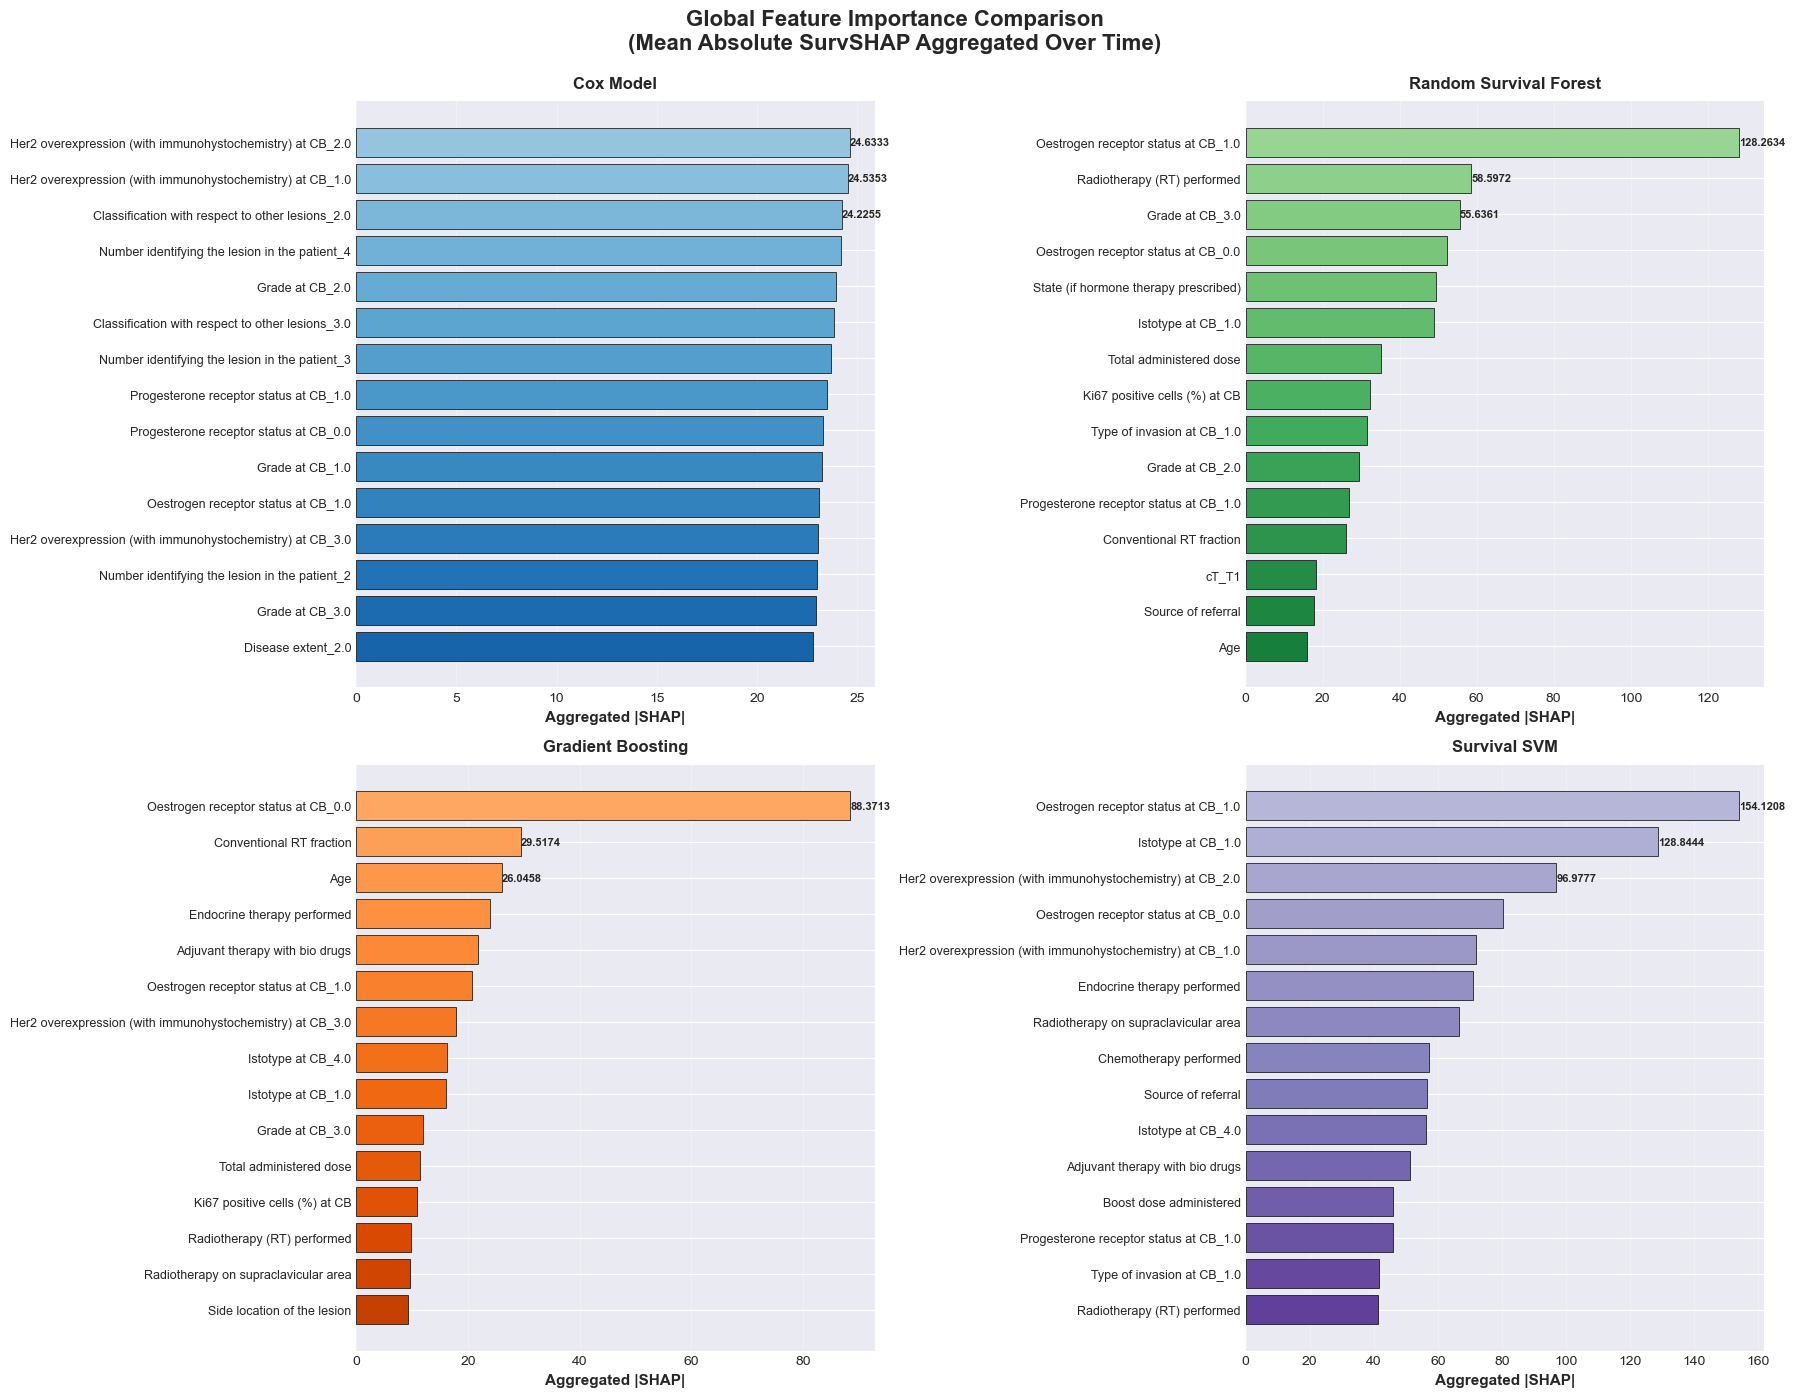

In [32]:
# Create 2x2 plot of global feature importance
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Global Feature Importance Comparison\n(Mean Absolute SurvSHAP Aggregated Over Time)', 
             fontsize=16, fontweight='bold', y=0.995)

models = [
    ('Cox Model', cox_global, axes[0, 0]),
    ('Random Survival Forest', rsf_global, axes[0, 1]),
    ('Gradient Boosting', gbm_global, axes[1, 0]),
    ('Survival SVM', ssvm_global, axes[1, 1])
]

top_n = 15
colors_map = {
    'Cox Model': plt.cm.Blues(np.linspace(0.4, 0.8, top_n)),
    'Random Survival Forest': plt.cm.Greens(np.linspace(0.4, 0.8, top_n)),
    'Gradient Boosting': plt.cm.Oranges(np.linspace(0.4, 0.8, top_n)),
    'Survival SVM': plt.cm.Purples(np.linspace(0.4, 0.8, top_n))
}

for model_name, data, ax in models:
    top_features = data.head(top_n)
    colors = colors_map[model_name]
    
    bars = ax.barh(range(top_n), top_features['aggregated_change'], color=colors, edgecolor='black', linewidth=0.5)
    ax.set_yticks(range(top_n))
    ax.set_yticklabels(top_features['variable_name'], fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel('Aggregated |SHAP|', fontsize=11, fontweight='bold')
    ax.set_title(model_name, fontsize=12, fontweight='bold', pad=10)
    ax.grid(True, alpha=0.3, axis='x')
    
    # Add value labels on bars
    for i, (bar, val) in enumerate(zip(bars, top_features['aggregated_change'])):
        if i < 3:  # Only label top 3
            ax.text(val, bar.get_y() + bar.get_height()/2, f'{val:.4f}', 
                   va='center', ha='left', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('comparison_global_importance.png', dpi=300, bbox_inches='tight')
print("✓ Global importance comparison saved to 'comparison_global_importance.png'")
plt.show()

## 4. Load Full Results for Time-Dependent Analysis

In [33]:
# Load full SHAP results (with time-dependent values)
cox_full = pd.read_csv('cox/cox_survshap_full_results.csv')
rsf_full = pd.read_csv('rsf/rsf_survshap_full_results.csv')
gbm_full = pd.read_csv('gbm/gbm_survshap_full_results.csv')
ssvm_full = pd.read_csv('ssvm/ssvm_survshap_full_results.csv')

print("Full results loaded:")
print(f"  Cox: {len(cox_full)} rows")
print(f"  RSF: {len(rsf_full)} rows")
print(f"  GBM: {len(gbm_full)} rows")
print(f"  SSVM: {len(ssvm_full)} rows")

Full results loaded:
  Cox: 2592 rows
  RSF: 67392 rows
  GBM: 124800 rows
  SSVM: 67392 rows


## 5. Comparative Plot: Time-Dependent SHAP (Top 5 Features)

✓ Time-dependent SHAP comparison saved to 'comparison_time_dependent_shap.png'


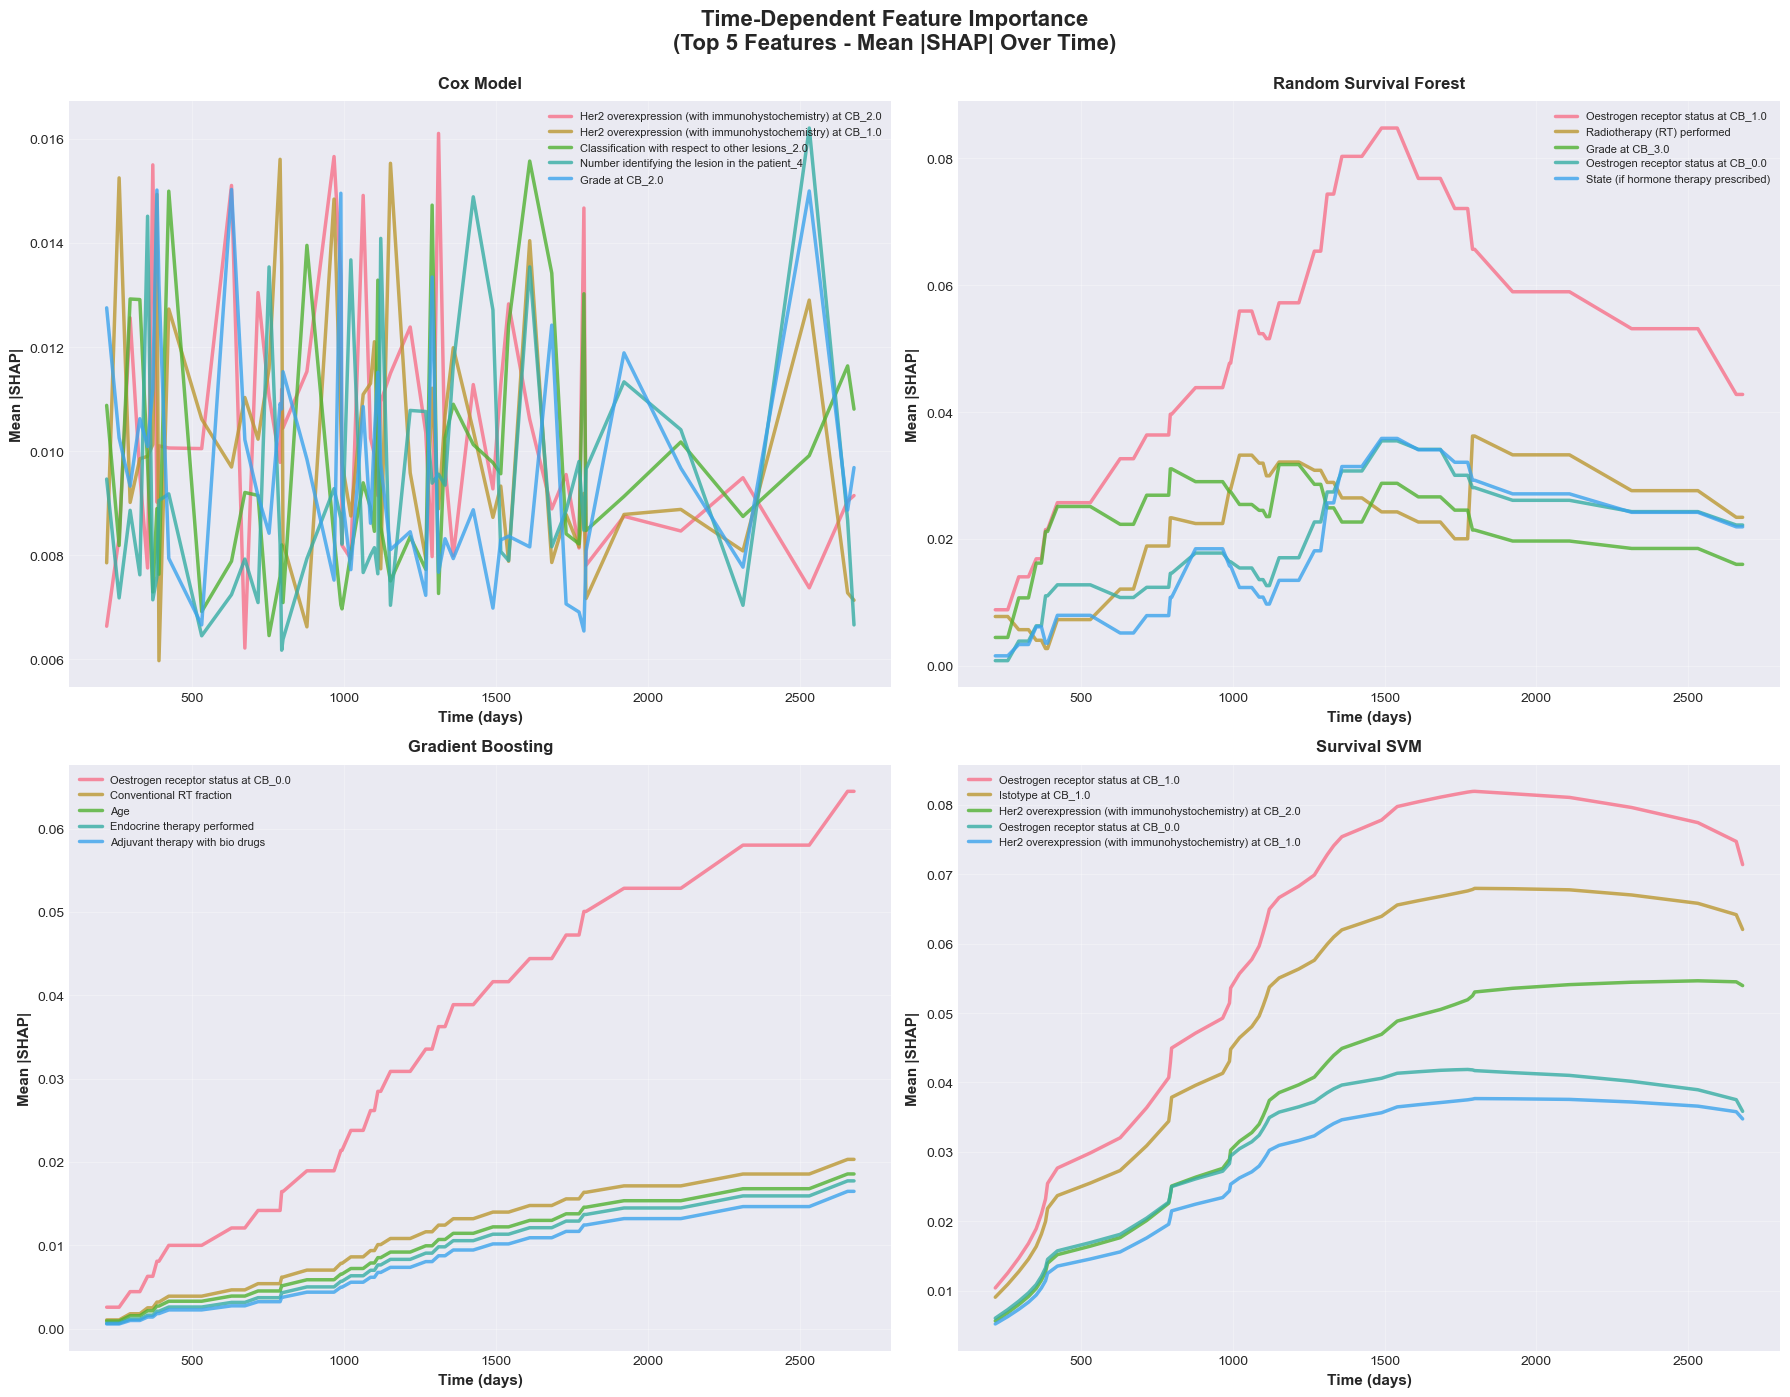

In [34]:
# Create 2x2 plot showing how top features' SHAP values change over time
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Time-Dependent Feature Importance\n(Top 5 Features - Mean |SHAP| Over Time)', 
             fontsize=16, fontweight='bold', y=0.995)

models_data = [
    ('Cox Model', cox_full, cox_global, cox_timestamps, axes[0, 0]),
    ('Random Survival Forest', rsf_full, rsf_global, rsf_timestamps, axes[0, 1]),
    ('Gradient Boosting', gbm_full, gbm_global, gbm_timestamps, axes[1, 0]),
    ('Survival SVM', ssvm_full, ssvm_global, ssvm_timestamps, axes[1, 1])
]

for model_name, full_data, global_data, timestamps, ax in models_data:
    # Get top 5 features
    top_5_features = global_data['variable_name'].head(5).tolist()
    
    # Extract time columns
    time_cols = [col for col in full_data.columns if isinstance(col, str) and col.startswith('t = ')]
    
    # Filter for B=0 (averaged path)
    result_b0 = full_data[full_data['B'] == 0]
    
    # Plot each top feature
    for feature in top_5_features:
        feature_data = result_b0[result_b0['variable_name'] == feature]
        if len(feature_data) > 0 and len(time_cols) > 0:
            # Get mean absolute SHAP across observations
            shap_values = feature_data[time_cols].abs().mean(axis=0).values
            n_points = min(len(timestamps), len(shap_values))
            ax.plot(timestamps[:n_points], shap_values[:n_points], linewidth=2.5, label=feature, alpha=0.8)
    
    ax.set_xlabel('Time (days)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Mean |SHAP|', fontsize=11, fontweight='bold')
    ax.set_title(model_name, fontsize=12, fontweight='bold', pad=10)
    ax.legend(loc='best', fontsize=8, framealpha=0.9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('comparison_time_dependent_shap.png', dpi=300, bbox_inches='tight')
print("✓ Time-dependent SHAP comparison saved to 'comparison_time_dependent_shap.png'")
plt.show()

## 6. Load Individual Patient Results (High/Low Risk)

In [35]:
# Load high and low risk patient results
try:
    cox_high = pd.read_csv('cox/cox_survshap_high_risk_patient.csv')
    cox_low = pd.read_csv('cox/cox_survshap_low_risk_patient.csv')
    rsf_high = pd.read_csv('rsf/rsf_survshap_high_risk_patient.csv')
    rsf_low = pd.read_csv('rsf/rsf_survshap_low_risk_patient.csv')
    gbm_high = pd.read_csv('gbm/gbm_survshap_high_risk_patient.csv')
    gbm_low = pd.read_csv('gbm/gbm_survshap_low_risk_patient.csv')
    ssvm_high = pd.read_csv('ssvm/ssvm_survshap_high_risk_patient.csv')
    ssvm_low = pd.read_csv('ssvm/ssvm_survshap_low_risk_patient.csv')
    
    print("✓ Individual patient results loaded successfully")
    individual_data_available = True
except FileNotFoundError as e:
    print(f"⚠ Individual patient files not found: {e}")
    print("Skipping individual patient comparison plots")
    individual_data_available = False

✓ Individual patient results loaded successfully


## 7. Comparative Plot: High-Risk Patient (Waterfall Plots)

✓ High-risk patient comparison saved to 'comparison_high_risk_patients.png'


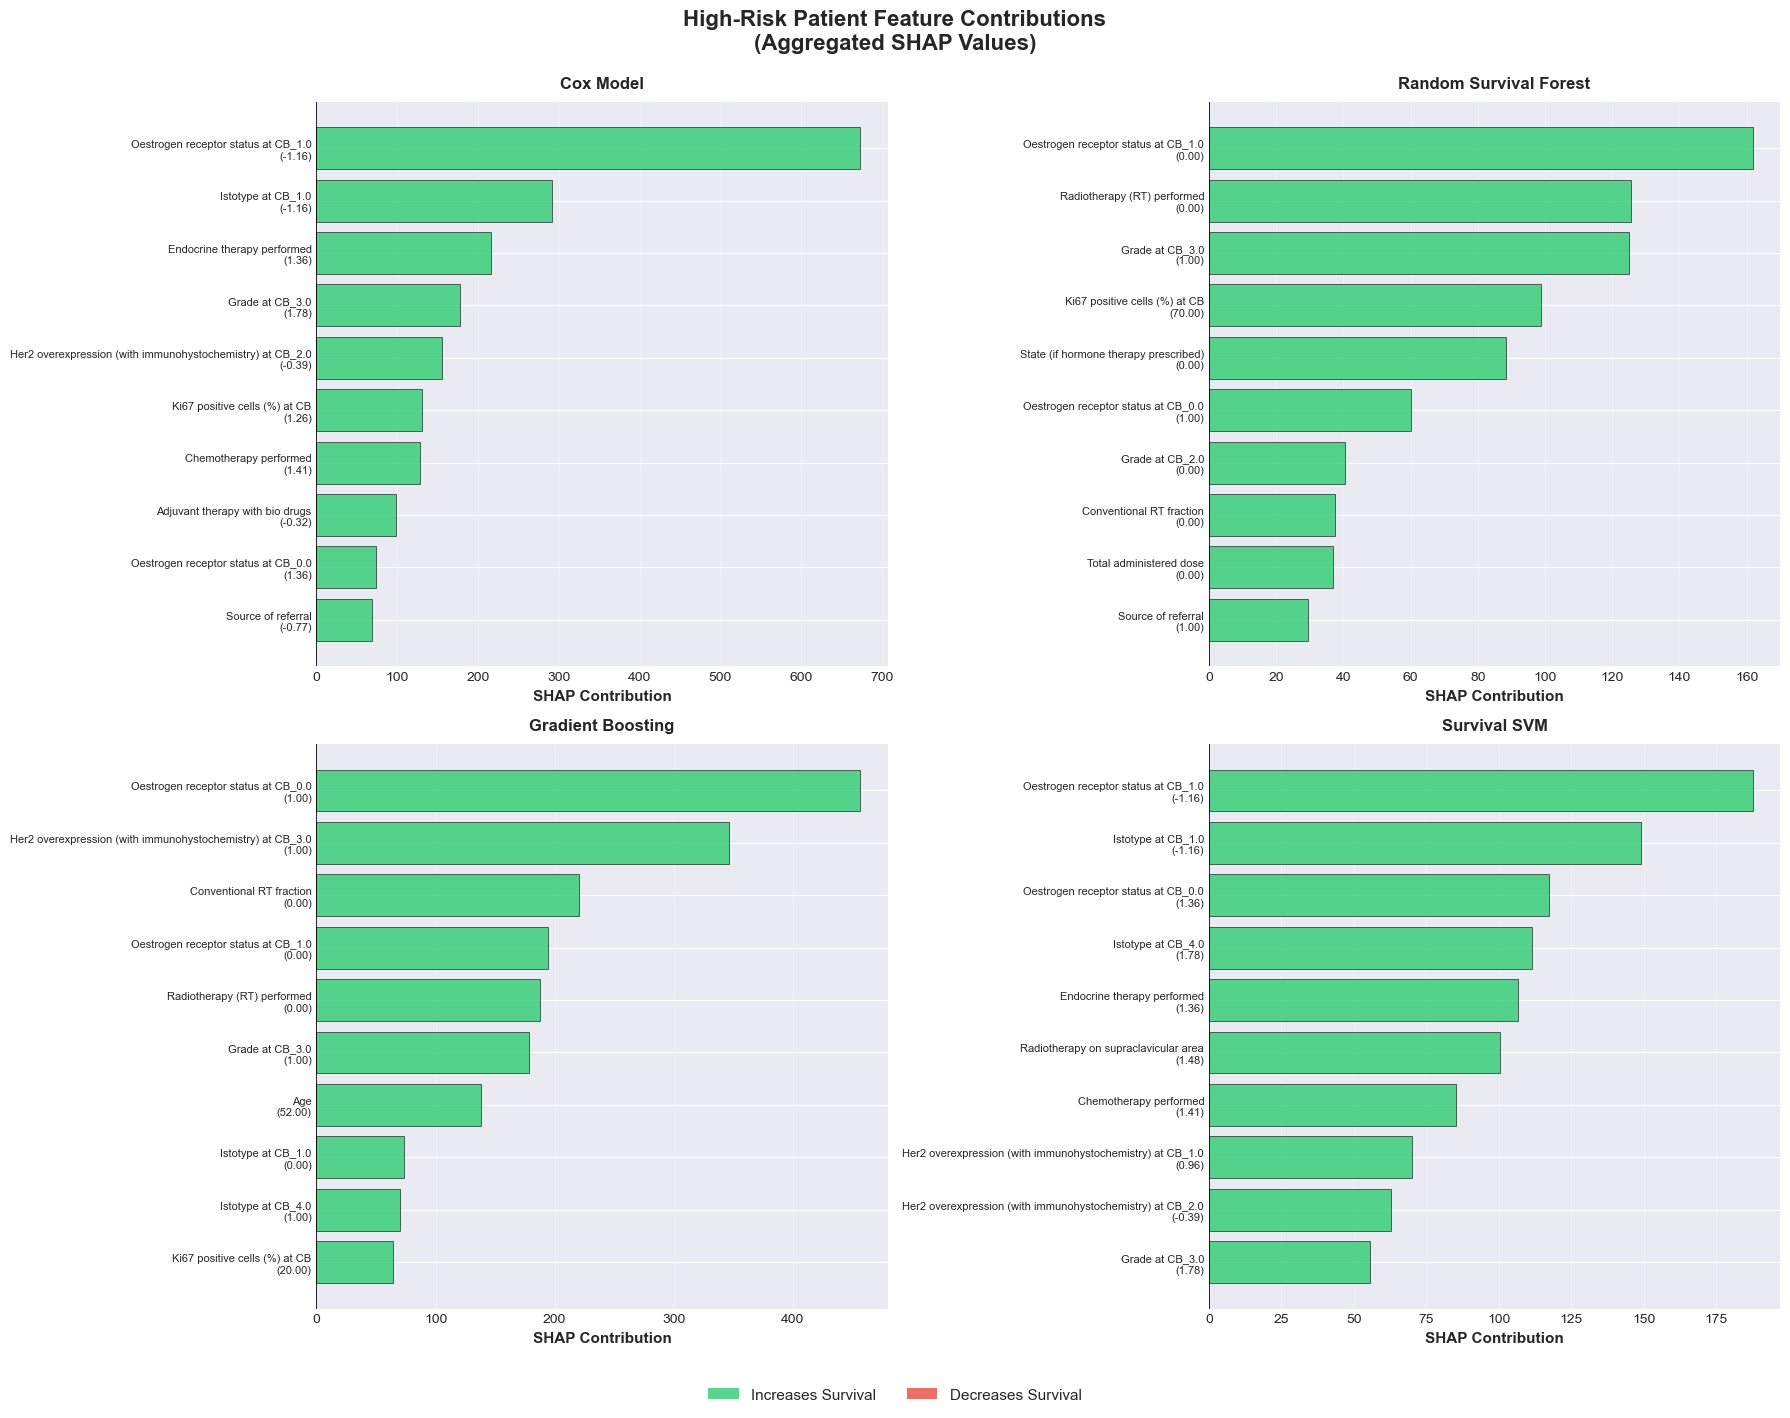

In [36]:
if individual_data_available:
    fig, axes = plt.subplots(2, 2, figsize=(18, 14))
    fig.suptitle('High-Risk Patient Feature Contributions\n(Aggregated SHAP Values)', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    models_high = [
        ('Cox Model', cox_high, axes[0, 0]),
        ('Random Survival Forest', rsf_high, axes[0, 1]),
        ('Gradient Boosting', gbm_high, axes[1, 0]),
        ('Survival SVM', ssvm_high, axes[1, 1])
    ]
    
    top_n = 10
    
    for model_name, data, ax in models_high:
        plot_data = data.head(top_n)
        
        colors = ['#e74c3c' if v < 0 else '#2ecc71' for v in plot_data['aggregated_change']]
        bars = ax.barh(range(top_n), plot_data['aggregated_change'], color=colors, alpha=0.8, edgecolor='black', linewidth=0.5)
        ax.set_yticks(range(top_n))
        ax.set_yticklabels([f"{name}\n({val:.2f})" for name, val in zip(plot_data['variable_name'], plot_data['variable_value'])], 
                          fontsize=8)
        ax.invert_yaxis()
        ax.axvline(0, color='black', linewidth=1.2)
        ax.set_xlabel('SHAP Contribution', fontsize=11, fontweight='bold')
        ax.set_title(model_name, fontsize=12, fontweight='bold', pad=10)
        ax.grid(True, alpha=0.3, axis='x')
    
    # Add legend
    legend_elements = [
        Patch(facecolor='#2ecc71', alpha=0.8, label='Increases Survival'),
        Patch(facecolor='#e74c3c', alpha=0.8, label='Decreases Survival')
    ]
    fig.legend(handles=legend_elements, loc='upper center', ncol=2, fontsize=11, 
              bbox_to_anchor=(0.5, 0.02), framealpha=0.9)
    
    plt.tight_layout(rect=[0, 0.03, 1, 1])
    plt.savefig('comparison_high_risk_patients.png', dpi=300, bbox_inches='tight')
    print("✓ High-risk patient comparison saved to 'comparison_high_risk_patients.png'")
    plt.show()

## 8. Comparative Plot: Low-Risk Patient (Waterfall Plots)

✓ Low-risk patient comparison saved to 'comparison_low_risk_patients.png'


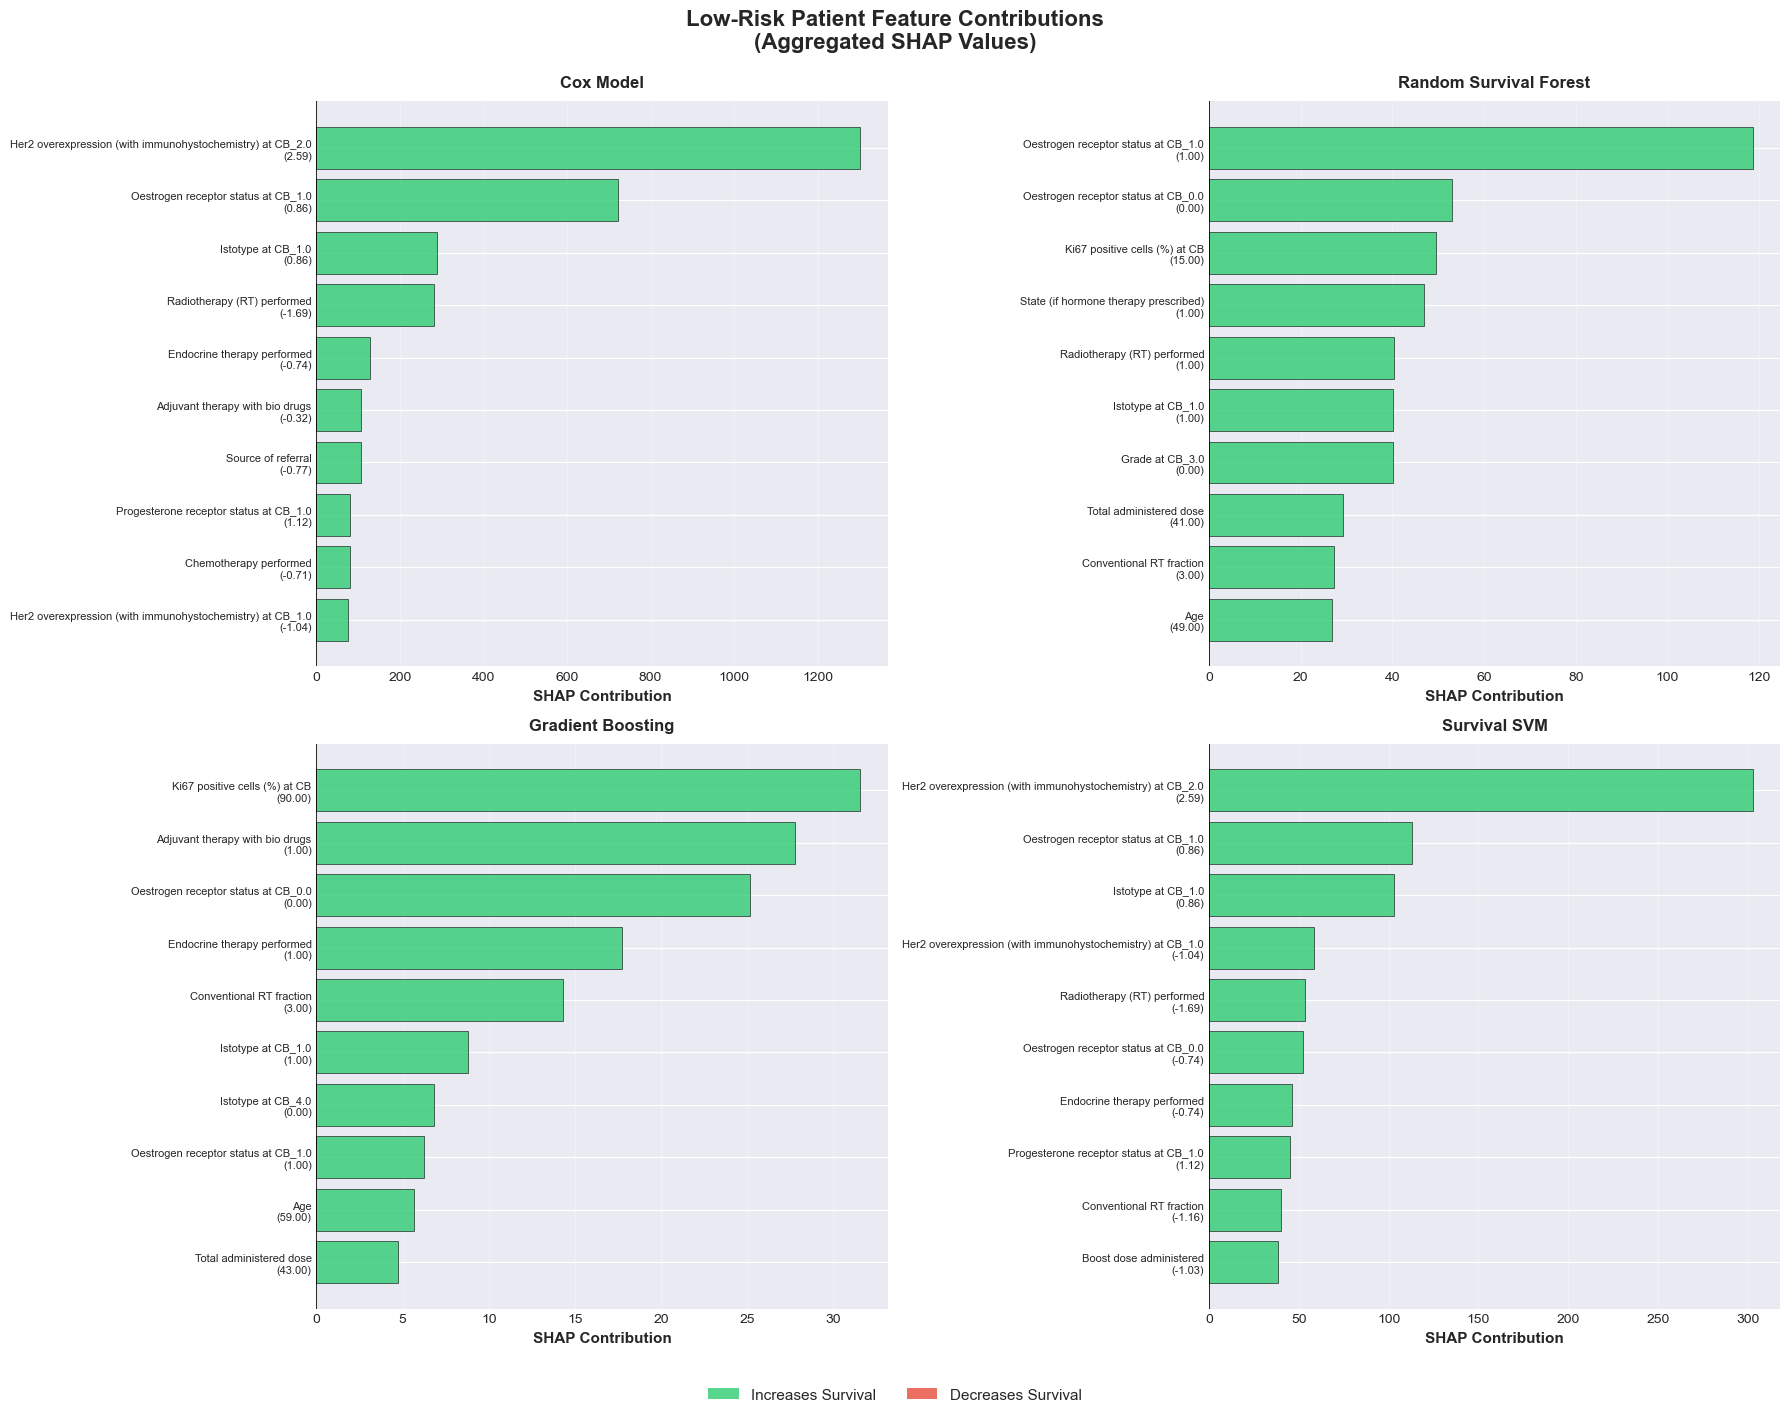

In [37]:
if individual_data_available:
    fig, axes = plt.subplots(2, 2, figsize=(18, 14))
    fig.suptitle('Low-Risk Patient Feature Contributions\n(Aggregated SHAP Values)', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    models_low = [
        ('Cox Model', cox_low, axes[0, 0]),
        ('Random Survival Forest', rsf_low, axes[0, 1]),
        ('Gradient Boosting', gbm_low, axes[1, 0]),
        ('Survival SVM', ssvm_low, axes[1, 1])
    ]
    
    top_n = 10
    
    for model_name, data, ax in models_low:
        plot_data = data.head(top_n)
        
        colors = ['#e74c3c' if v < 0 else '#2ecc71' for v in plot_data['aggregated_change']]
        bars = ax.barh(range(top_n), plot_data['aggregated_change'], color=colors, alpha=0.8, edgecolor='black', linewidth=0.5)
        ax.set_yticks(range(top_n))
        ax.set_yticklabels([f"{name}\n({val:.2f})" for name, val in zip(plot_data['variable_name'], plot_data['variable_value'])], 
                          fontsize=8)
        ax.invert_yaxis()
        ax.axvline(0, color='black', linewidth=1.2)
        ax.set_xlabel('SHAP Contribution', fontsize=11, fontweight='bold')
        ax.set_title(model_name, fontsize=12, fontweight='bold', pad=10)
        ax.grid(True, alpha=0.3, axis='x')
    
    # Add legend
    legend_elements = [
        Patch(facecolor='#2ecc71', alpha=0.8, label='Increases Survival'),
        Patch(facecolor='#e74c3c', alpha=0.8, label='Decreases Survival')
    ]
    fig.legend(handles=legend_elements, loc='upper center', ncol=2, fontsize=11, 
              bbox_to_anchor=(0.5, 0.02), framealpha=0.9)
    
    plt.tight_layout(rect=[0, 0.03, 1, 1])
    plt.savefig('comparison_low_risk_patients.png', dpi=300, bbox_inches='tight')
    print("✓ Low-risk patient comparison saved to 'comparison_low_risk_patients.png'")
    plt.show()

In [38]:
# Load time-dependent results for individual patients
if individual_data_available:
    try:
        # Load high-risk patient full results (with time columns)
        cox_high_full = pd.read_csv('cox/cox_survshap_high_risk_full.csv')
        cox_low_full = pd.read_csv('cox/cox_survshap_low_risk_full.csv')
        rsf_high_full = pd.read_csv('rsf/rsf_survshap_high_risk_full.csv')
        rsf_low_full = pd.read_csv('rsf/rsf_survshap_low_risk_full.csv')
        gbm_high_full = pd.read_csv('gbm/gbm_survshap_high_risk_full.csv')
        gbm_low_full = pd.read_csv('gbm/gbm_survshap_low_risk_full.csv')
        ssvm_high_full = pd.read_csv('ssvm/ssvm_survshap_high_risk_full.csv')
        ssvm_low_full = pd.read_csv('ssvm/ssvm_survshap_low_risk_full.csv')
        
        print("✓ Individual patient time-dependent results loaded successfully")
        time_dependent_individual_available = True
    except FileNotFoundError as e:
        print(f"⚠ Individual patient time-dependent files not found: {e}")
        print("Skipping individual patient time-dependent plots")
        time_dependent_individual_available = False
else:
    time_dependent_individual_available = False
    print("⚠ Individual patient data not available - skipping time-dependent plots")

✓ Individual patient time-dependent results loaded successfully


## 11. Comparative Plot: Low-Risk Patient Time-Dependent SHAP

✓ High-risk patient time-dependent comparison saved to 'comparison_high_risk_time_dependent.png'


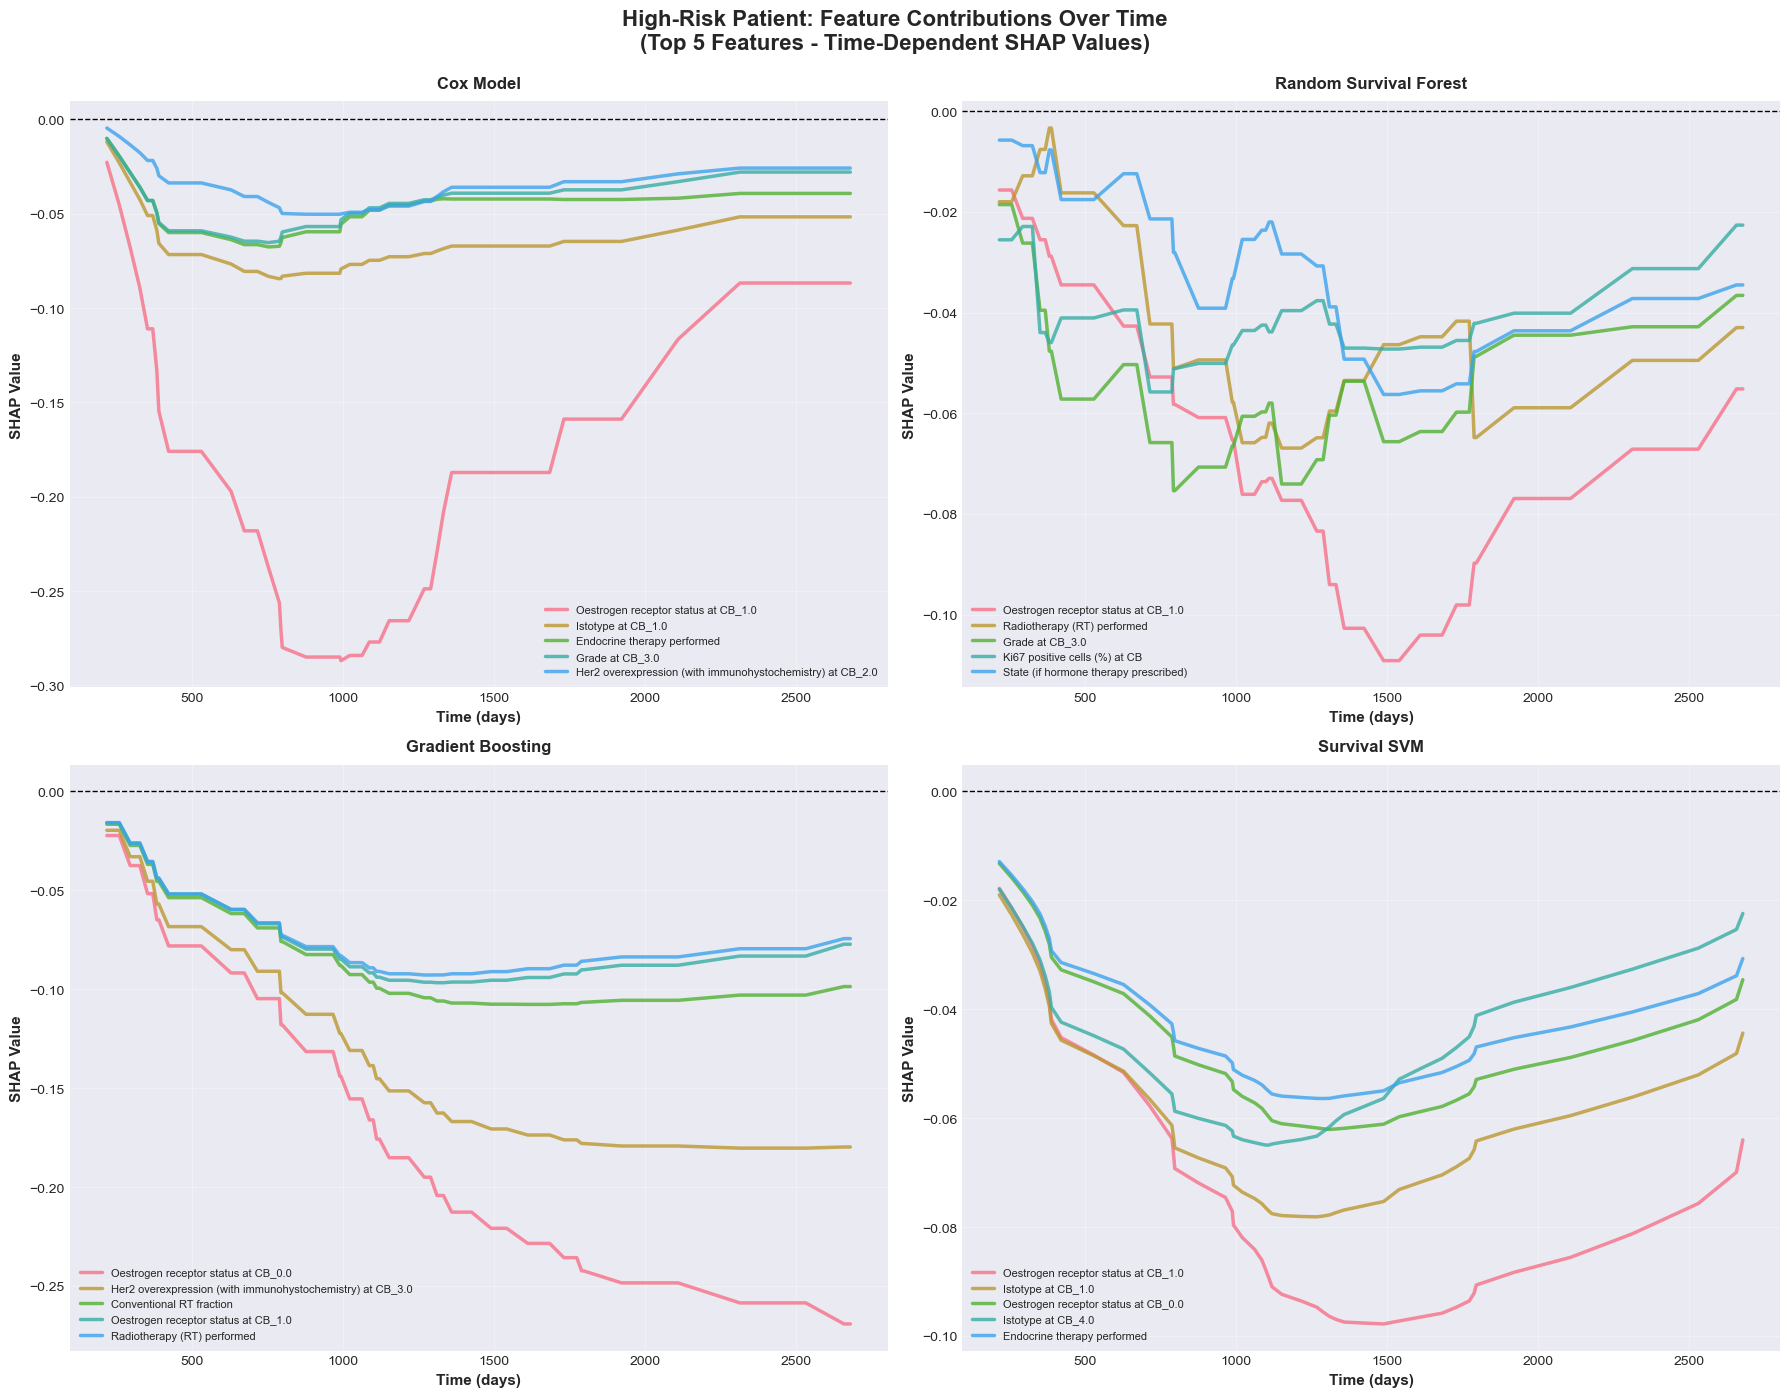

In [39]:
if time_dependent_individual_available:
    fig, axes = plt.subplots(2, 2, figsize=(18, 14))
    fig.suptitle('High-Risk Patient: Feature Contributions Over Time\n(Top 5 Features - Time-Dependent SHAP Values)', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    models_high_time = [
        ('Cox Model', cox_high_full, cox_high, cox_timestamps, axes[0, 0]),
        ('Random Survival Forest', rsf_high_full, rsf_high, rsf_timestamps, axes[0, 1]),
        ('Gradient Boosting', gbm_high_full, gbm_high, gbm_timestamps, axes[1, 0]),
        ('Survival SVM', ssvm_high_full, ssvm_high, ssvm_timestamps, axes[1, 1])
    ]
    
    for model_name, full_data, simplified_data, timestamps, ax in models_high_time:
        # Get top 5 features for this patient
        top_5_features = simplified_data['variable_name'].head(5).tolist()
        
        # Extract time columns
        time_cols = [col for col in full_data.columns if isinstance(col, str) and col.startswith('t = ')]
        
        # Filter for B=0 (averaged path)
        result_b0 = full_data[full_data['B'] == 0]
        
        # Plot each top feature over time
        for feature in top_5_features:
            feature_row = result_b0[result_b0['variable_name'] == feature]
            if len(feature_row) > 0 and len(time_cols) > 0:
                shap_values = feature_row[time_cols].values.flatten()
                n_points = min(len(timestamps), len(shap_values))
                ax.plot(timestamps[:n_points], shap_values[:n_points], linewidth=2.5, label=feature, alpha=0.8)
        
        ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.set_xlabel('Time (days)', fontsize=11, fontweight='bold')
        ax.set_ylabel('SHAP Value', fontsize=11, fontweight='bold')
        ax.set_title(model_name, fontsize=12, fontweight='bold', pad=10)
        ax.legend(loc='best', fontsize=8, framealpha=0.9)
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('comparison_high_risk_time_dependent.png', dpi=300, bbox_inches='tight')
    print("✓ High-risk patient time-dependent comparison saved to 'comparison_high_risk_time_dependent.png'")
    plt.show()

✓ Low-risk patient time-dependent comparison saved to 'comparison_low_risk_time_dependent.png'


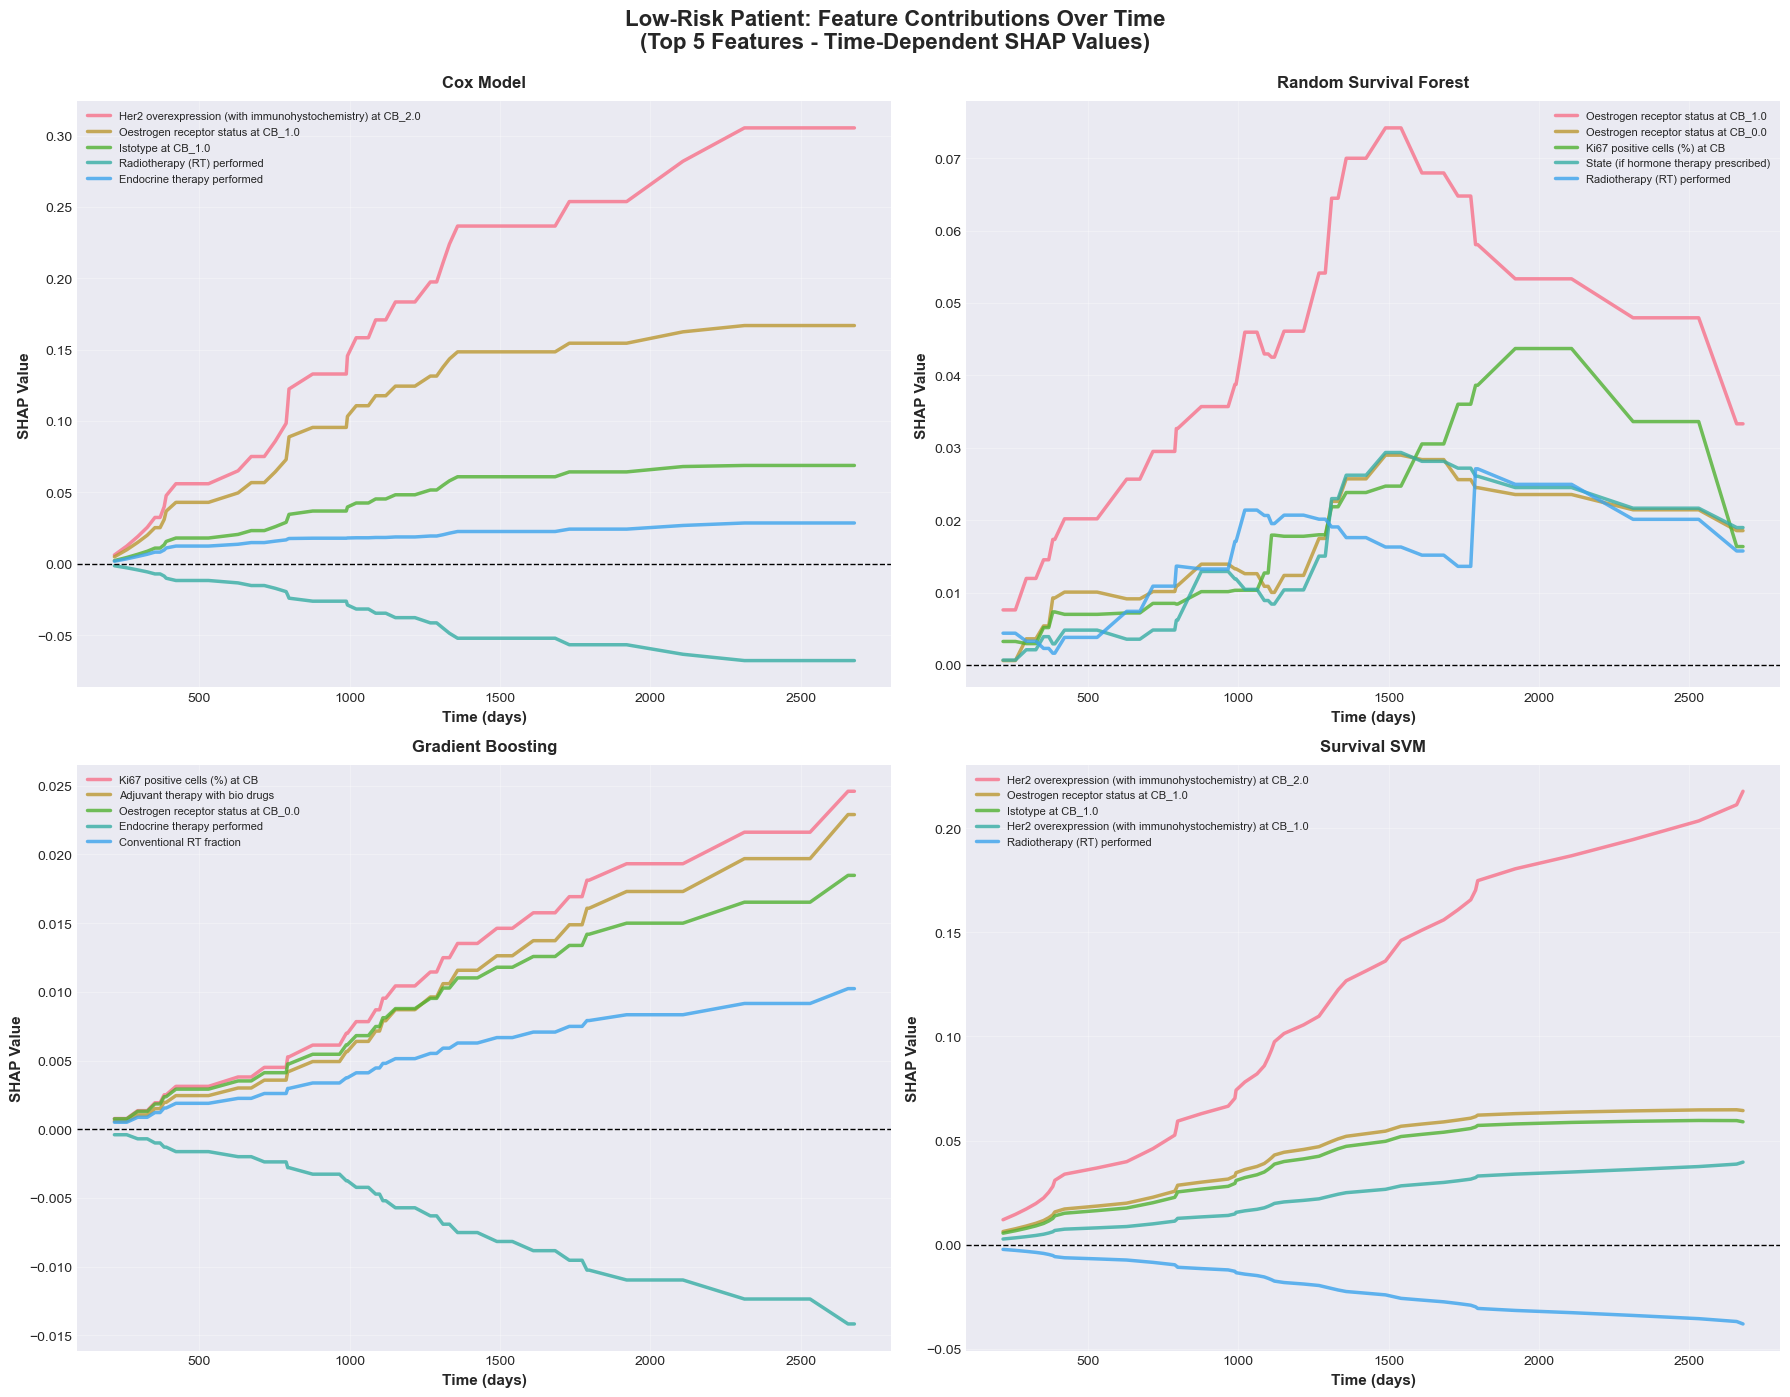

In [40]:
if time_dependent_individual_available:
    fig, axes = plt.subplots(2, 2, figsize=(18, 14))
    fig.suptitle('Low-Risk Patient: Feature Contributions Over Time\n(Top 5 Features - Time-Dependent SHAP Values)', 
                 fontsize=16, fontweight='bold', y=0.995)
    
    models_low_time = [
        ('Cox Model', cox_low_full, cox_low, cox_timestamps, axes[0, 0]),
        ('Random Survival Forest', rsf_low_full, rsf_low, rsf_timestamps, axes[0, 1]),
        ('Gradient Boosting', gbm_low_full, gbm_low, gbm_timestamps, axes[1, 0]),
        ('Survival SVM', ssvm_low_full, ssvm_low, ssvm_timestamps, axes[1, 1])
    ]
    
    for model_name, full_data, simplified_data, timestamps, ax in models_low_time:
        # Get top 5 features for this patient
        top_5_features = simplified_data['variable_name'].head(5).tolist()
        
        # Extract time columns
        time_cols = [col for col in full_data.columns if isinstance(col, str) and col.startswith('t = ')]
        
        # Filter for B=0 (averaged path)
        result_b0 = full_data[full_data['B'] == 0]
        
        # Plot each top feature over time
        for feature in top_5_features:
            feature_row = result_b0[result_b0['variable_name'] == feature]
            if len(feature_row) > 0 and len(time_cols) > 0:
                shap_values = feature_row[time_cols].values.flatten()
                n_points = min(len(timestamps), len(shap_values))
                ax.plot(timestamps[:n_points], shap_values[:n_points], linewidth=2.5, label=feature, alpha=0.8)
        
        ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.set_xlabel('Time (days)', fontsize=11, fontweight='bold')
        ax.set_ylabel('SHAP Value', fontsize=11, fontweight='bold')
        ax.set_title(model_name, fontsize=12, fontweight='bold', pad=10)
        ax.legend(loc='best', fontsize=8, framealpha=0.9)
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('comparison_low_risk_time_dependent.png', dpi=300, bbox_inches='tight')
    print("✓ Low-risk patient time-dependent comparison saved to 'comparison_low_risk_time_dependent.png'")
    plt.show()

## 15. Summary Report

In [44]:
print("\n" + "="*70)
print("SHAP COMPARISON SUMMARY")
print("="*70)

print("\n📊 Generated Comparison Plots:")
print("  1. comparison_global_importance.png")
print("  2. comparison_time_dependent_shap.png")
if individual_data_available:
    print("  3. comparison_high_risk_patients.png")
    print("  4. comparison_low_risk_patients.png")
if time_dependent_individual_available:
    print("  5. comparison_high_risk_time_dependent.png")
    print("  6. comparison_low_risk_time_dependent.png")
print("  7. comparison_feature_agreement_heatmap.png")
print("  8. comparison_rank_correlation.png")

print("\n📁 Generated Data Files:")
print("  1. feature_agreement_matrix.csv")
print("  2. feature_rank_correlations.csv")

print("\n🔍 Key Findings:")
print(f"  • {len(all_models)} features consistently important across ALL 4 models")
print(f"  • {len(three_plus)} features important in at least 3 models")
print(f"  • Average rank correlation: {corr_matrix[np.triu_indices_from(corr_matrix, k=1)].mean():.3f}")

print("\n✓ SHAP comparison analysis completed successfully!")
print("="*70)


SHAP COMPARISON SUMMARY

📊 Generated Comparison Plots:
  1. comparison_global_importance.png
  2. comparison_time_dependent_shap.png
  3. comparison_high_risk_patients.png
  4. comparison_low_risk_patients.png
  5. comparison_high_risk_time_dependent.png
  6. comparison_low_risk_time_dependent.png
  7. comparison_feature_agreement_heatmap.png
  8. comparison_rank_correlation.png

📁 Generated Data Files:
  1. feature_agreement_matrix.csv
  2. feature_rank_correlations.csv

🔍 Key Findings:
  • 0 features consistently important across ALL 4 models
  • 3 features important in at least 3 models
  • Average rank correlation: 0.210

✓ SHAP comparison analysis completed successfully!
